# Retail orders: ingestion, cleaning and preprocessing with pandas

**Goal.** Take a messy, real-world-style orders dataset (10,000+ rows) with missing values, duplicates and wrong data types, clean it, engineer features, and export `clean_dataset.csv`, with before/after evidence at every step.

> **About the data (please read).** The files uploaded for this task (`retail-orders-raw_1.csv`) contain only **12 rows**, the same small sample as before, and have no cost column. The brief needs 10,000+ rows and a profit margin. So this notebook cleans a **synthetic 12,400-row messy dataset** (`retail-orders-messy-12k.csv`) generated by `generate_messy_retail_orders.py` (seed 42): same 9 columns plus `unit_cost`, with realistic defects injected on purpose. The cleaning pipeline is a set of reusable functions, and section 10 re-runs it on **your actual 12-row file** (no cost column there, so margin uses an assumed cost ratio, clearly flagged). To clean your own 10k+ file, change `DATA_FILE` in the first code cell and *Run All*.

| Section | What it shows |
|---|---|
| 1-2 | Setup, rules from the data dictionary, load raw data |
| 3 | Profile **before**: missing values, duplicates, types, label chaos, outliers |
| 4 | Cleaning pipeline, one step per cell, each step logged |
| 5 | Feature engineering: month/year, quarter, weekday, revenue, cost, profit margin |
| 6 | Validation: assertions that the clean data meets the rules |
| 7 | **Before vs after** metrics and charts |
| 8-9 | Export `clean_dataset.csv`, cleaning log and dropped-rows audit |
| 10 | Same pipeline on the uploaded 12-row file |

## 1. Setup and cleaning rules

In [1]:
import re, difflib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 220); pd.set_option("display.max_columns", 50); pd.set_option("display.max_colwidth", 80)

DATA_FILE = Path("retail-orders-messy-12k.csv")     # <- point this at any file with the same schema
DICT_FILE = Path("retail-data-dictionary.csv")
SAMPLE_FILE = Path("retail-orders-raw.csv")         # the 12-row file that was uploaded

# ---- rules (from the data dictionary below) ---------------------------------------------------------------
AS_OF = pd.Timestamp("2026-10-16")                  # fixed "today" so the run is reproducible
MIN_DATE = pd.Timestamp("2025-01-01")
MAX_QTY = 20                                        # a single learning-product order above this is treated as an error
MAX_GAP_DAYS = 7                                    # max span between neighbouring orders for a date to be inferred
PRICE_RATIO_RANGE = (0.5, 2.0)                      # valid unit_price = 0.5x to 2x the category's usual (modal) price
COST_RATIO_RANGE = (0.05, 1.5)                      # valid unit_cost = 5% to 150% of the unit price
ASSUMED_COST_RATIO = {"Learning Kit": 0.55, "Course Access": 0.30, "Mentor Session": 0.45}   # ONLY used if no unit_cost column
SEGMENTS = ["Student", "Fresher", "Professional"]
CATEGORIES = ["Learning Kit", "Course Access", "Mentor Session"]
STATUSES = ["Paid", "Pending", "Failed", "Refunded"]
CITIES = ["Bengaluru", "Hyderabad", "Chennai", "Mumbai", "Delhi", "Pune", "Kochi", "Kolkata"]
SEGMENT_ALIASES = {"stud": "Student", "freshers": "Fresher", "prof": "Professional", "pro": "Professional"}
CITY_ALIASES = {"bangalore": "Bengaluru", "blr": "Bengaluru", "bombay": "Mumbai", "madras": "Chennai", "new delhi": "Delhi",
                "hyd": "Hyderabad", "cochin": "Kochi", "calcutta": "Kolkata"}
CATEGORY_ALIASES = {}
STATUS_ALIASES = {"success": "Paid", "completed": "Paid", "complete": "Paid", "awaiting": "Pending",
                  "fail": "Failed", "failure": "Failed", "refund": "Refunded"}
MISSING_TOKENS = {"", "na", "n/a", "#n/a", "nan", "null", "none", "-", "--", "?", "missing", "unknown"}
WORDS = {"zero": 0, "one": 1, "two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10}
DATE_FORMATS = [("YYYY-MM-DD", r"^\d{4}-\d{2}-\d{2}$", "%Y-%m-%d"), ("DD/MM/YYYY", r"^\d{2}/\d{2}/\d{4}$", "%d/%m/%Y"),
                ("DD-Mon-YYYY", r"^\d{2}-[A-Za-z]{3}-\d{4}$", "%d-%b-%Y"), ("YYYY/MM/DD", r"^\d{4}/\d{2}/\d{2}$", "%Y/%m/%d")]

pd.read_csv(DICT_FILE)

,column,data_type,business_definition,quality_rule
0,order_id,string,Unique order identifier,Required and unique
1,order_date,date,Date the customer placed the order,Required ISO date between 2025-01-01 and today
2,customer_segment,category,Commercial customer segment,Student Fresher or Professional after normalization
3,city,string,Customer billing city,Required non-empty text
4,category,category,Product family,Learning Kit Course Access or Mentor Session
5,quantity,integer,Units purchased,Whole number greater than zero
6,unit_price,decimal,Price per unit before discount,Non-negative INR amount
7,discount_pct,decimal,Percentage discount applied,Between 0 and 100; missing means zero only after justification
8,payment_status,category,Latest order settlement state,Paid Pending Failed or Refunded after normalization


## 2. Ingest the raw file
Everything is read as **text** (`dtype=str`) so pandas cannot silently coerce or drop anything before we have looked at it.

In [2]:
raw = pd.read_csv(DATA_FILE, dtype=str, keep_default_na=False)
print(f"{raw.shape[0]:,} rows x {raw.shape[1]} columns   (file: {DATA_FILE})")
display(raw.head(12))
raw.info()

12,400 rows x 10 columns   (file: retail-orders-messy-12k.csv)


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,unit_cost
0,RT-10001,2025-01-01,Fresher,bengaluru,Learning Kit,1,799,0,Paid,408.09
1,RT-10002,2025-01-01,Student,Delhi,Learning Kit,1,799,0,Paid,478.71
2,RT-10003,2025-01-01,Fresher,NA,Mentor Session,1,999,0,paid,406.00
3,RT-10004,2025-01-01,Student,Hyderabad,Learning Kit,2,799,0,Paid,396.33
4,RT-10005,01-Jan-2025,Student,Pune,Learning Kit,2,799,0,Paid,431.16
5,RT-10006,2025-01-01,Fresher,NA,Learning Kit,1,799,10,Paid,406.14
6,RT-10007,2025-01-01,Fresher,Kochi,Learning Kit,4,799,0,Paid,412.61
7,RT-10008,2025-01-01,Professional,Chennai,course_access,4,1499,5,Paid,₹430.60
8,RT-10009,2025-01-01,Professional,Bengaluru,Learning Kit,1,799,0,Paid,-
9,RT-10010,01-Jan-2025,PROFESSIONAL,Bengaluru,Mentor Session,1,999,0,Paid,484.61


<class 'pandas.DataFrame'>
RangeIndex: 12400 entries, 0 to 12399
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   order_id          12400 non-null  str  
 1   order_date        12400 non-null  str  
 2   customer_segment  12400 non-null  str  
 3   city              12400 non-null  str  
 4   category          12400 non-null  str  
 5   quantity          12400 non-null  str  
 6   unit_price        12400 non-null  str  
 7   discount_pct      12400 non-null  str  
 8   payment_status    12400 non-null  str  
 9   unit_cost         12400 non-null  str  
dtypes: str(10)
memory usage: 968.9 KB


## 3. Profile BEFORE cleaning
First normalise the many spellings of "missing" (`""`, `N/A`, `null`, `-` ...) into real nulls, so missingness can be counted honestly. Values are not otherwise touched.

In [3]:
def tidy_text(df):
    """Trim whitespace, collapse internal spaces, turn missing-value tokens into NaN."""
    out = df.copy()
    for c in out.columns:
        s = out[c].str.strip().str.replace(r"\s+", " ", regex=True)
        out[c] = s.mask(s.str.lower().isin(MISSING_TOKENS))
    return out

def to_number(s):
    """Parse text to float: strips currency symbols, thousands separators and %, understands 'two', 'three' ..."""
    t = s.str.lower().str.replace(r"rs\.?|inr|₹|\$|,|%", "", regex=True).str.strip()
    a = pd.to_numeric(t, errors="coerce").to_numpy(dtype="float64", na_value=np.nan)
    b = pd.to_numeric(t.map(WORDS), errors="coerce").to_numpy(dtype="float64", na_value=np.nan)
    return pd.Series(np.where(np.isnan(a), b, a), index=s.index)

def classify_dates(s):
    label = pd.Series("unrecognised", index=s.index, dtype="object")
    for name, pat, _ in DATE_FORMATS: label[s.str.match(pat, na=False)] = name
    label[s.isna()] = "missing"
    return label

def parse_dates(s):
    out = pd.Series(pd.NaT, index=s.index, dtype="datetime64[ns]")
    for name, pat, fmt in DATE_FORMATS:
        m = s.str.match(pat, na=False)
        if m.any(): out.loc[m] = pd.to_datetime(s[m], format=fmt, errors="coerce").astype("datetime64[ns]")
    return out

t = tidy_text(raw)
print("Missing values per column (after normalising tokens):")
miss_before = t.isna().sum()
display(pd.DataFrame({"missing": miss_before, "missing_%": (100 * miss_before / len(t)).round(2)}))
print(f"Exact duplicate rows: {raw.duplicated().sum():,}    |    extra rows sharing an order_id: {t['order_id'].dropna().duplicated().sum():,}")

Missing values per column (after normalising tokens):


,missing,missing_%
order_id,11,0.09
order_date,153,1.23
customer_segment,116,0.94
city,237,1.91
category,76,0.61
quantity,109,0.88
unit_price,179,1.44
discount_pct,913,7.36
payment_status,62,0.50
unit_cost,354,2.85


Exact duplicate rows: 300    |    extra rows sharing an order_id: 400


In [4]:
print("Date formats in use:")
display(classify_dates(t["order_date"]).value_counts().rename("rows").to_frame())

print("Label chaos in categorical columns (distinct spellings that should be only a handful):")
display(pd.DataFrame({"distinct_labels": [t[c].nunique() for c in ["customer_segment", "city", "category", "payment_status"]],
                      "expected": [3, 8, 3, 4]}, index=["customer_segment", "city", "category", "payment_status"]))
display(t["city"].value_counts().head(15).rename("rows").to_frame().T)

Date formats in use:


,rows
YYYY-MM-DD,10457
DD/MM/YYYY,917
DD-Mon-YYYY,743
missing,153
YYYY/MM/DD,130


Label chaos in categorical columns (distinct spellings that should be only a handful):


,distinct_labels,expected
customer_segment,13,3
city,30,8
category,14,3
payment_status,19,4


city,Bengaluru,Hyderabad,Chennai,Delhi,Mumbai,Pune,Kolkata,Kochi,hyderabad,HYDERABAD,mumbai,Madras,Hyd,chennai,New Delhi
rows,2347,1658,1592,1539,1524,833,618,410,113,101,94,93,93,91,87


In [5]:
def numeric_profile(t):
    rules = {"quantity": lambda n: (n <= 0) | (n % 1 != 0) | (n > MAX_QTY), "unit_price": lambda n: n <= 0,
             "discount_pct": lambda n: (n < 0) | (n > 100), "unit_cost": lambda n: n <= 0}
    rows = []
    for col, rule in rules.items():
        if col not in t: continue
        s = t[col]; n = to_number(s); present = s.notna()
        q1, q3 = n.quantile([.25, .75]); iqr = q3 - q1
        rows.append({"column": col, "present": int(present.sum()),
                     "unparseable_text": int((present & n.isna()).sum()),
                     "text_needing_cleanup (symbols, words, %, commas)": int((present & n.notna() & ~s.str.fullmatch(r"-?\d+(\.\d+)?", na=False)).sum()),
                     "breaks_business_rule": int((n.notna() & rule(n)).sum()),
                     "flagged_by_IQR_1.5": int((n.notna() & ((n < q1 - 1.5 * iqr) | (n > q3 + 1.5 * iqr))).sum())})
    return pd.DataFrame(rows).set_index("column")
display(numeric_profile(t))
print("Note: IQR flags legitimate values too (e.g. quantity 4-5 and the higher list prices), so cleaning uses explicit domain rules,")
print("with the IQR column kept as a cross-check.")

,present,unparseable_text,"text_needing_cleanup (symbols, words, %, commas)",breaks_business_rule,flagged_by_IQR_1.5
column,,,,,
quantity,12291,0,63,82,1034
unit_price,12221,0,411,42,57
discount_pct,11487,0,358,51,36
unit_cost,12046,0,130,22,54


Note: IQR flags legitimate values too (e.g. quantity 4-5 and the higher list prices), so cleaning uses explicit domain rules,
with the IQR column kept as a cross-check.


**Date ambiguity check.** `03/01/2026` could be 3 January (DD/MM) or 1 March (MM/DD). Because order numbers are sequential and orders rise with time, we can test which reading lands closer to the neighbouring ISO-dated orders.

In [6]:
seq = t["order_id"].str.extract(r"(\d+)")[0].astype(float)
order = seq.dropna().sort_values(kind="stable").index
iso = parse_dates(t["order_date"].where(t["order_date"].str.match(DATE_FORMATS[0][1], na=False)))
iso = iso.where(iso.between(MIN_DATE, AS_OF))
p = iso.loc[order]; ref = p.ffill() + (p.bfill() - p.ffill()) / 2
d = t.loc[order, "order_date"]
slash = d.str.match(r"^\d{2}/\d{2}/\d{4}$", na=False)
dd, mm, yy = (pd.to_numeric(d.str[a:b], errors="coerce") for a, b in [(0, 2), (3, 5), (6, 10)])
amb = slash & (dd <= 12) & (mm <= 12) & (dd != mm)
dmy = pd.to_datetime(pd.DataFrame({"year": yy, "month": mm, "day": dd}), errors="coerce")
mdy = pd.to_datetime(pd.DataFrame({"year": yy, "month": dd, "day": mm}), errors="coerce")
sel = amb & ref.notna() & dmy.notna() & mdy.notna()
share = ((dmy - ref).abs() < (mdy - ref).abs())[sel].mean() if sel.any() else float("nan")
print(f"{int(sel.sum())} ambiguous slash-dates tested; DD/MM is the closer reading to neighbouring orders for {share:.1%} of them")
print("-> decision: parse slash dates as DD/MM/YYYY (Indian source system), and log it.")

380 ambiguous slash-dates tested; DD/MM is the closer reading to neighbouring orders for 100.0% of them
-> decision: parse slash dates as DD/MM/YYYY (Indian source system), and log it.


### Before-metrics snapshot
Saved now so section 7 can compare against the clean data on exactly the same yardsticks.

In [7]:
def audit_raw(raw, t):
    pr = to_number(t["unit_price"]); q = to_number(t["quantity"]); dsc = to_number(t["discount_pct"])
    cst = to_number(t["unit_cost"]) if "unit_cost" in t else pd.Series(dtype=float)
    dates = parse_dates(t["order_date"])
    return {
        "Rows": len(raw),
        "Exact duplicate rows": int(raw.duplicated().sum()),
        "Extra rows sharing an order_id": int(t["order_id"].dropna().duplicated().sum()),
        "Missing cells": int(t.isna().sum().sum()),
        "Columns stored as text (before: every column)": int(raw.shape[1]),
        "Distinct date formats": int(classify_dates(t["order_date"]).isin([f[0] for f in DATE_FORMATS]).groupby(classify_dates(t["order_date"])).any().sum()),
        "Invalid / out-of-range dates": int((t["order_date"].notna() & ~dates.between(MIN_DATE, AS_OF)).sum()),
        "Distinct segment labels": int(t["customer_segment"].nunique()),
        "Distinct city labels": int(t["city"].nunique()),
        "Distinct category labels": int(t["category"].nunique()),
        "Distinct status labels": int(t["payment_status"].nunique()),
        "Invalid quantities": int((t["quantity"].notna() & (q.isna() | (q <= 0) | (q % 1 != 0) | (q > MAX_QTY))).sum()),
        "Invalid prices (<= 0)": int((t["unit_price"].notna() & (pr.isna() | (pr <= 0))).sum()),
        "Invalid discounts (outside 0-100)": int((t["discount_pct"].notna() & (dsc.isna() | (dsc < 0) | (dsc > 100))).sum()),
        "Invalid unit_cost (<= 0)": int((t["unit_cost"].notna() & (cst.isna() | (cst <= 0))).sum()) if "unit_cost" in t else 0,
    }
BEFORE = audit_raw(raw, t)
BEFORE_NUM = {"unit_price": to_number(t["unit_price"]), "quantity": to_number(t["quantity"])}
pd.Series(BEFORE, name="before").to_frame()

,before
Rows,12400
Exact duplicate rows,300
Extra rows sharing an order_id,400
Missing cells,2210
Columns stored as text (before: every column),10
Distinct date formats,4
Invalid / out-of-range dates,78
Distinct segment labels,13
Distinct city labels,30
Distinct category labels,14


## 4. Cleaning pipeline
Each step is a function that takes the frame, writes to an **audit log** (what was wrong, how many cells/rows, what was done) and records any dropped rows with a reason, so nothing disappears silently. Raw values are never overwritten in the source frame.

**Principles used:** fix what is deterministic (formats, casing, spelling variants); infer only with a defensible rule and flag it; never fabricate silently; drop only what cannot be placed (no id, or no recoverable date).

In [8]:
LOG, DROPPED = [], []
def make_logger(store):
    def log(step, issue, n, action):
        store.append({"step": step, "issue": issue, "affected": int(n), "action": action})
    return log
log = make_logger(LOG)
def show_log(step, store=None):
    return pd.DataFrame(store if store is not None else LOG).query("step == @step").drop(columns="step").reset_index(drop=True)

def safe_mode(s):
    s = s.dropna()
    return s.mode().iat[0] if len(s) else np.nan

### Step 1: Order ids and duplicates
Missing ids cannot be recovered, so those rows are dropped. **Exact** duplicates keep the first copy. Rows that repeat an `order_id` with **different** content are re-exports of the same order; the file is in export order, so the **latest row wins**.

In [9]:
def step_ids_duplicates(df, log, dropped):
    df = df.copy()
    df["order_id"] = df["order_id"].str.upper()
    no_id = df["order_id"].isna() | ~df["order_id"].str.match(r"^RT-\d+$", na=False)
    dropped.append(df[no_id].assign(drop_reason="missing or malformed order_id"))
    log("1 ids & duplicates", "missing / malformed order_id", no_id.sum(), "row dropped (cannot be identified)")
    df = df[~no_id]
    exact = df.duplicated(keep="first")
    dropped.append(df[exact].assign(drop_reason="exact duplicate row"))
    log("1 ids & duplicates", "exact duplicate rows", exact.sum(), "kept first copy, dropped the rest")
    df = df[~exact]
    older = df.duplicated("order_id", keep="last")
    kept = df[~older].set_index("order_id")
    changed = (df.loc[older, "payment_status"].fillna("").values != kept.loc[df.loc[older, "order_id"], "payment_status"].fillna("").values).sum()
    dropped.append(df[older].assign(drop_reason="superseded by a later row with the same order_id"))
    log("1 ids & duplicates", "same order_id, different content (conflicting re-export)", older.sum(), f"kept latest row; {changed} of them differed in payment_status")
    return df[~older]

c1 = step_ids_duplicates(t, log, DROPPED)
print(f"rows: {len(t):,} -> {len(c1):,}   | order_id unique: {c1['order_id'].is_unique}")
show_log("1 ids & duplicates")

rows: 12,400 -> 11,989   | order_id unique: True


,issue,affected,action
0,missing / malformed order_id,11,row dropped (cannot be identified)
1,exact duplicate rows,300,"kept first copy, dropped the rest"
2,"same order_id, different content (conflicting re-export)",100,kept latest row; 100 of them differed in payment_status


### Step 2: Dates
Four formats are parsed explicitly (no guessing parser). Impossible calendar dates, unrecognised formats and dates outside the allowed range become null, then are **inferred from neighbouring orders** (order numbers are sequential): the midpoint of the previous and next valid dates if they are at most 7 days apart. Rows whose date still cannot be placed are dropped. Every inferred date is flagged `date_imputed`.

In [10]:
def step_dates(df, log, dropped):
    df = df.copy()
    s = df["order_date"]
    fmt = classify_dates(s); parsed = parse_dates(s)
    non_iso = (fmt.isin([f[0] for f in DATE_FORMATS[1:]]) & parsed.notna()).sum()
    bad_cal = (fmt.isin([f[0] for f in DATE_FORMATS]) & parsed.isna()).sum()
    oor = parsed.notna() & ~parsed.between(MIN_DATE, AS_OF)
    log("2 dates", "non-ISO formats (DD/MM/YYYY, DD-Mon-YYYY, YYYY/MM/DD)", non_iso, "parsed with explicit formats, stored as real dates")
    log("2 dates", "impossible calendar dates (month 13, 30 Feb, month 00)", bad_cal, "set to null")
    log("2 dates", "unrecognised date text", (fmt == "unrecognised").sum(), "set to null")
    log("2 dates", f"outside {MIN_DATE.date()} .. {AS_OF.date()}", oor.sum(), "set to null")
    log("2 dates", "missing order_date", (fmt == "missing").sum(), "set to null")
    parsed = parsed.mask(oor)
    seq = df["order_id"].str.extract(r"(\d+)")[0].astype("int64")
    order = seq.sort_values(kind="stable").index
    p = parsed.loc[order]; prev, nxt = p.ffill(), p.bfill()
    both = prev.notna() & nxt.notna()
    fill = pd.Series(pd.NaT, index=order, dtype="datetime64[ns]")
    ok = both & ((nxt - prev).dt.days <= MAX_GAP_DAYS)
    fill[ok] = (prev + (nxt - prev) / 2).dt.floor("D")[ok]
    one = prev.notna() ^ nxt.notna()
    fill[one] = prev[one].fillna(nxt[one])
    imputed = p.isna() & fill.notna()
    parsed.loc[imputed[imputed].index] = fill[imputed]
    df["date_imputed"] = df.index.isin(imputed[imputed].index)
    log("2 dates", "null dates inferred from neighbouring orders", imputed.sum(), "midpoint of neighbours (<= 7 days apart), flagged date_imputed")
    df["order_date"] = parsed
    lost = df["order_date"].isna()
    dropped.append(df[lost].assign(drop_reason="order_date missing/invalid and not inferable"))
    log("2 dates", "still no date after inference", lost.sum(), "row dropped")
    return df[~lost]

c2 = step_dates(c1, log, DROPPED)
print(f"rows: {len(c1):,} -> {len(c2):,}   | dtype of order_date: {c2['order_date'].dtype}   | range: {c2['order_date'].min().date()} .. {c2['order_date'].max().date()}")
show_log("2 dates")

rows: 11,989 -> 11,989   | dtype of order_date: datetime64[ns]   | range: 2025-01-01 .. 2026-10-10


,issue,affected,action
0,"non-ISO formats (DD/MM/YYYY, DD-Mon-YYYY, YYYY/MM/DD)",1710,"parsed with explicit formats, stored as real dates"
1,"impossible calendar dates (month 13, 30 Feb, month 00)",49,set to null
2,unrecognised date text,0,set to null
3,outside 2025-01-01 .. 2026-10-16,24,set to null
4,missing order_date,148,set to null
5,null dates inferred from neighbouring orders,221,"midpoint of neighbours (<= 7 days apart), flagged date_imputed"
6,still no date after inference,0,row dropped


### Step 3: Categorical labels
Case, whitespace and punctuation are normalised; known aliases (Bangalore → Bengaluru, Success → Paid) are mapped; remaining typos are resolved by **fuzzy matching** (`difflib`, 80% similarity) to the allowed list. Segment and status that cannot be resolved become `Unknown`; city is an open set, so unresolved cities are kept (title-cased) rather than discarded. Category stays null for now: step 4 can infer it from the price.

In [11]:
def nk(x):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", x.lower())).strip() if isinstance(x, str) else np.nan

def standardise(series, canon, aliases, cutoff=0.8, open_set=False):
    key = series.map(nk)
    lookup = {nk(c): c for c in canon}; lookup.update({nk(k): v for k, v in aliases.items()})
    resolved = {}
    for k in key.dropna().unique():
        if k in lookup: resolved[k] = lookup[k]
        else:
            m = difflib.get_close_matches(k, list(lookup), n=1, cutoff=cutoff)
            resolved[k] = lookup[m[0]] if m else (k.title() if open_set else np.nan)
    return key.map(resolved)

def step_categoricals(df, log, dropped):
    df = df.copy()
    specs = [("customer_segment", SEGMENTS, SEGMENT_ALIASES, False), ("city", CITIES, CITY_ALIASES, True),
             ("category", CATEGORIES, CATEGORY_ALIASES, False), ("payment_status", STATUSES, STATUS_ALIASES, False)]
    for col, canon, aliases, open_set in specs:
        before = df[col]; after = standardise(before, canon, aliases, open_set=open_set)
        changed = (before.notna() & (before != after)).sum()
        unresolved = (before.notna() & after.isna()).sum()
        log("3 categoricals", f"{col}: {before.nunique()} spellings -> {after.nunique()} labels", changed, "case/whitespace/alias/fuzzy standardisation")
        if unresolved: log("3 categoricals", f"{col}: unresolvable values", unresolved, "set to null, then 'Unknown'" if col != "category" else "set to null")
        df[col] = after
    for col in ["customer_segment", "city", "payment_status"]:
        n = df[col].isna().sum()
        log("3 categoricals", f"{col}: missing", n, "labelled 'Unknown' (not guessed)")
        df[col] = df[col].fillna("Unknown")
    return df

c3 = step_categoricals(c2, log, DROPPED)
display(show_log("3 categoricals"))
display(pd.DataFrame({"before (spellings)": [c2[c].nunique() for c in ["customer_segment", "city", "category", "payment_status"]],
                      "after (labels)": [c3[c].nunique() for c in ["customer_segment", "city", "category", "payment_status"]]},
                     index=["customer_segment", "city", "category", "payment_status"]))
display(pd.DataFrame({"raw": c2["city"], "standardised": c3["city"]}).groupby(["raw", "standardised"]).size().rename("rows").reset_index().query("raw != standardised").head(12))

,issue,affected,action
0,customer_segment: 13 spellings -> 3 labels,911,case/whitespace/alias/fuzzy standardisation
1,city: 30 spellings -> 8 labels,1592,case/whitespace/alias/fuzzy standardisation
2,category: 14 spellings -> 3 labels,862,case/whitespace/alias/fuzzy standardisation
3,payment_status: 19 spellings -> 4 labels,1175,case/whitespace/alias/fuzzy standardisation
4,customer_segment: missing,109,labelled 'Unknown' (not guessed)
5,city: missing,225,labelled 'Unknown' (not guessed)
6,payment_status: missing,60,labelled 'Unknown' (not guessed)


,before (spellings),after (labels)
customer_segment,13,4
city,30,9
category,14,3
payment_status,19,5


,raw,standardised,rows
0,BANGALORE,Bengaluru,63
1,BLR,Bengaluru,68
2,Bangalore,Bengaluru,63
4,Bombay,Mumbai,75
5,CHENNAI,Chennai,77
6,Calcutta,Kolkata,44
8,Cochin,Kochi,28
9,DELHI,Delhi,71
11,HYDERABAD,Hyderabad,98
12,Hyd,Hyderabad,90


### Step 4: Numbers, outliers and imputation
Order of operations matters here:

1. **Parse** text numbers (`₹799`, `1,499`, `10%`, `two`, `2.0`); anything unparseable or breaking a rule becomes null.
2. **Price outliers** (e.g. 7,990 instead of 799) are found relative to the category's usual price (the mode of valid prices).
3. **Category from price**: where category is missing but the price matches exactly one category's list price, the category is inferred.
4. **Impute**: price → category's usual price; quantity → category mode; discount → category median (a missing discount is *not* blindly zero, it is the typical observed value, and the log shows how often that value is zero); `unit_cost` → category median cost ratio × price.
5. Every substituted value is flagged (`price_fixed`, `qty_fixed`, `discount_fixed`, `cost_fixed`, `category_inferred`).

In [12]:
def step_numbers(df, log, dropped):
    df = df.copy()
    q = to_number(df["quantity"]); pr = to_number(df["unit_price"]); ds = to_number(df["discount_pct"])
    # --- quantity
    fmt_fix = (df["quantity"].notna() & ~df["quantity"].str.fullmatch(r"\d+", na=False) & q.notna() & (q > 0) & (q % 1 == 0) & (q <= MAX_QTY)).sum()
    log("4 numbers", "quantity written as words / decimals ('two', '2.0')", fmt_fix, "converted to integer")
    q_bad = df["quantity"].notna() & (q.isna() | (q <= 0) | (q % 1 != 0) | (q > MAX_QTY))
    log("4 numbers", f"quantity <= 0, fractional, unparseable or > {MAX_QTY} (outliers)", q_bad.sum(), "set to null, then imputed")
    q = q.mask(q_bad)
    # --- price
    p_fmt = (df["unit_price"].notna() & ~df["unit_price"].str.fullmatch(r"\d+", na=False) & pr.notna() & (pr > 0)).sum()
    log("4 numbers", "unit_price with symbols / commas / decimals ('₹799', '1,499', '799.00')", p_fmt, "converted to number")
    p_bad = df["unit_price"].notna() & (pr.isna() | (pr <= 0))
    log("4 numbers", "unit_price <= 0 or unparseable", p_bad.sum(), "set to null, then imputed")
    pr = pr.mask(p_bad)
    cat = df["category"]
    modes = pr.groupby(cat).agg(safe_mode).dropna()
    ratio = pr / cat.map(modes)
    p_out = pr.notna() & ratio.notna() & ((ratio < PRICE_RATIO_RANGE[0]) | (ratio > PRICE_RATIO_RANGE[1]))
    log("4 numbers", "unit_price outliers vs category's usual price (e.g. x10 typos)", p_out.sum(), "set to null, then imputed")
    pr = pr.mask(p_out)
    # --- category from price
    inv = {v: k for k, v in modes.items()}
    infer = cat.isna() & pr.notna() & pr.isin(list(inv))
    cat = cat.where(~infer, pr.map(inv))
    df["category_inferred"] = infer
    log("4 numbers", "category missing but price matches one category exactly", infer.sum(), "category inferred from price, flagged category_inferred")
    # --- impute price
    p_fix = pr.isna() & cat.notna()
    df["price_fixed"] = p_fix
    pr = pr.where(~p_fix, cat.map(modes))
    log("4 numbers", "unit_price imputed with the category's usual price", p_fix.sum(), "flagged price_fixed")
    unresolved = pr.isna()
    dropped.append(df[unresolved].assign(drop_reason="no price and no category: revenue cannot be computed"))
    log("4 numbers", "price AND category both unknown", unresolved.sum(), "row dropped")
    keep = ~unresolved
    df, q, pr, ds, cat = df[keep], q[keep], pr[keep], ds[keep], cat[keep]
    df["category"] = cat.fillna("Unknown")
    # --- quantity impute
    q_mode = q.groupby(df["category"]).agg(safe_mode); g_mode = safe_mode(q)
    df["qty_fixed"] = q.isna()
    q = q.fillna(df["category"].map(q_mode)).fillna(g_mode)
    log("4 numbers", "quantity imputed with the category mode", df["qty_fixed"].sum(), "flagged qty_fixed")
    # --- discount
    d_fmt = (df["discount_pct"].notna() & ~df["discount_pct"].str.fullmatch(r"\d+", na=False) & ds.notna() & (ds >= 0) & (ds <= 100)).sum()
    log("4 numbers", "discount written as '10%' / '10.0'", d_fmt, "converted to number")
    d_bad = df["discount_pct"].notna() & (ds.isna() | (ds < 0) | (ds > 100))
    log("4 numbers", "discount outside 0-100 (e.g. 105, 150, -10)", d_bad.sum(), "set to null, then imputed")
    ds = ds.mask(d_bad)
    zero_share = (ds.dropna() == 0).mean()
    d_med = ds.groupby(df["category"]).median(); g_med = ds.median()
    df["discount_fixed"] = ds.isna()
    ds = ds.fillna(df["category"].map(d_med)).fillna(g_med)
    log("4 numbers", f"discount missing/invalid -> imputed with category median ({zero_share:.0%} of valid discounts are 0)", df["discount_fixed"].sum(), "flagged discount_fixed")
    df["quantity"] = q.astype("int64"); df["unit_price"] = pr.astype("float64"); df["discount_pct"] = ds.astype("float64")
    # --- unit_cost
    if "unit_cost" in df:
        cs = to_number(df["unit_cost"])
        c_fmt = (df["unit_cost"].notna() & ~df["unit_cost"].str.fullmatch(r"\d+(\.\d+)?", na=False) & cs.notna() & (cs > 0)).sum()
        log("4 numbers", "unit_cost with currency symbols", c_fmt, "converted to number")
        cr = cs / df["unit_price"]
        c_bad = df["unit_cost"].notna() & (cs.isna() | (cs <= 0) | (cr < COST_RATIO_RANGE[0]) | (cr > COST_RATIO_RANGE[1]))
        log("4 numbers", "unit_cost <= 0 or outside 5%-150% of price (e.g. x10 typos)", c_bad.sum(), "set to null, then imputed")
        cs = cs.mask(c_bad); cr = cs / df["unit_price"]
        med_ratio = cr.groupby(df["category"]).median(); g_ratio = cr.median()
        df["cost_fixed"] = cs.isna()
        cs = cs.fillna(df["category"].map(med_ratio).fillna(g_ratio) * df["unit_price"])
        df["margin_basis"] = np.where(df["cost_fixed"], "imputed cost", "reported cost")
        log("4 numbers", "unit_cost missing/invalid -> category median cost ratio x price", df["cost_fixed"].sum(), "flagged cost_fixed, margin_basis = 'imputed cost'")
    else:
        cs = df["category"].map(ASSUMED_COST_RATIO).fillna(0.45) * df["unit_price"]
        df["cost_fixed"] = True; df["margin_basis"] = "assumed cost ratio"
        log("4 numbers", "no unit_cost column in source", len(df), "cost = ASSUMED_COST_RATIO x price; margin_basis = 'assumed cost ratio' (illustrative only)")
    df["unit_cost"] = cs.astype("float64")
    return df

c4 = step_numbers(c3, log, DROPPED)
display(show_log("4 numbers"))
print(f"rows: {len(c3):,} -> {len(c4):,}")
display(c4[["quantity", "unit_price", "discount_pct", "unit_cost"]].describe().round(2))

,issue,affected,action
0,"quantity written as words / decimals ('two', '2.0')",183,converted to integer
1,"quantity <= 0, fractional, unparseable or > 20 (outliers)",80,"set to null, then imputed"
2,"unit_price with symbols / commas / decimals ('₹799', '1,499', '799.00')",750,converted to number
3,unit_price <= 0 or unparseable,41,"set to null, then imputed"
4,unit_price outliers vs category's usual price (e.g. x10 typos),34,"set to null, then imputed"
5,category missing but price matches one category exactly,73,"category inferred from price, flagged category_inferred"
6,unit_price imputed with the category's usual price,248,flagged price_fixed
7,price AND category both unknown,0,row dropped
8,quantity imputed with the category mode,186,flagged qty_fixed
9,discount written as '10%' / '10.0',680,converted to number


rows: 11,989 -> 11,989


,quantity,unit_price,discount_pct,unit_cost
count,11989.00,11989.00,11989.00,11989.00
mean,1.74,1088.63,5.51,445.10
std,1.03,314.45,7.18,25.64
min,1.00,799.00,0.00,395.51
25%,1.00,799.00,0.00,423.65
50%,1.00,999.00,0.00,445.36
75%,2.00,1499.00,10.00,466.13
max,5.00,1499.00,25.00,494.67


## 5. Feature engineering
Date parts for time analysis and the revenue / cost / profit chain. **Profit margin** is order-level gross profit ÷ net revenue; `margin_basis` records whether the cost behind it was reported, imputed or assumed.

In [13]:
def step_features(df, log):
    df = df.copy()
    d = df["order_date"]
    df["order_year"] = d.dt.year.astype("int64")
    df["order_month"] = d.dt.month.astype("int64")
    df["order_month_name"] = d.dt.month_name()
    df["order_quarter"] = d.dt.quarter.astype("int64")
    df["order_year_month"] = d.dt.strftime("%Y-%m")
    df["order_weekday"] = d.dt.day_name()
    df["is_weekend"] = d.dt.dayofweek >= 5
    df["gross_revenue"] = df["quantity"] * df["unit_price"]
    df["discount_amount"] = df["gross_revenue"] * df["discount_pct"] / 100
    df["net_revenue"] = df["gross_revenue"] - df["discount_amount"]
    df["total_cost"] = df["quantity"] * df["unit_cost"]
    df["gross_profit"] = df["net_revenue"] - df["total_cost"]
    df["profit_margin_pct"] = np.where(df["net_revenue"] > 0, df["gross_profit"] / df["net_revenue"] * 100, np.nan)
    df["is_paid"] = df["payment_status"] == "Paid"
    df["discount_band"] = pd.cut(df["discount_pct"], [-0.1, 0, 10, 20, 100], labels=["0%", "1-10%", "11-20%", ">20%"]).astype(str)
    df["n_fixes"] = df[["date_imputed", "category_inferred", "price_fixed", "qty_fixed", "discount_fixed"]].sum(axis=1) + (df["margin_basis"] == "imputed cost")
    log("5 features", "engineered columns added", 14, "order_year/month/month_name/quarter/year_month/weekday, is_weekend, revenue, discount, cost, profit, margin %, is_paid, discount_band")
    return df

c5 = step_features(c4, log)
display(c5[["order_id", "order_date", "order_year", "order_month", "order_quarter", "order_weekday", "quantity", "unit_price", "discount_pct",
            "net_revenue", "total_cost", "gross_profit", "profit_margin_pct", "margin_basis"]].head(8).round({"net_revenue": 2, "total_cost": 2, "gross_profit": 2, "profit_margin_pct": 2}))

,order_id,order_date,order_year,order_month,order_quarter,order_weekday,quantity,unit_price,discount_pct,net_revenue,total_cost,gross_profit,profit_margin_pct,margin_basis
0,RT-10001,2025-01-01,2025,1,1,Wednesday,1,799.0,0.0,799.0,408.09,390.91,48.92,reported cost
1,RT-10002,2025-01-01,2025,1,1,Wednesday,1,799.0,0.0,799.0,478.71,320.29,40.09,reported cost
2,RT-10003,2025-01-01,2025,1,1,Wednesday,1,999.0,0.0,999.0,406.00,593.00,59.36,reported cost
3,RT-10004,2025-01-01,2025,1,1,Wednesday,2,799.0,0.0,1598.0,792.66,805.34,50.40,reported cost
4,RT-10005,2025-01-01,2025,1,1,Wednesday,2,799.0,0.0,1598.0,862.32,735.68,46.04,reported cost
5,RT-10006,2025-01-01,2025,1,1,Wednesday,1,799.0,10.0,719.1,406.14,312.96,43.52,reported cost
6,RT-10007,2025-01-01,2025,1,1,Wednesday,4,799.0,0.0,3196.0,1650.44,1545.56,48.36,reported cost
7,RT-10008,2025-01-01,2025,1,1,Wednesday,4,1499.0,5.0,5696.2,1722.40,3973.80,69.76,reported cost


### Assemble the final dataset
Final column order, proper dtypes (dates, integers, floats, categories, booleans), rounded money columns, original file order restored.

In [14]:
FINAL_COLS = ["order_id", "order_date", "order_year", "order_month", "order_month_name", "order_quarter", "order_year_month", "order_weekday", "is_weekend",
              "customer_segment", "city", "category", "quantity", "unit_price", "discount_pct", "discount_band", "payment_status", "is_paid",
              "unit_cost", "gross_revenue", "discount_amount", "net_revenue", "total_cost", "gross_profit", "profit_margin_pct", "margin_basis",
              "date_imputed", "category_inferred", "price_fixed", "qty_fixed", "discount_fixed", "cost_fixed", "n_fixes"]

def finalize(df):
    out = df.sort_index()[FINAL_COLS].reset_index(drop=True)
    for c in ["customer_segment", "city", "category", "payment_status", "discount_band", "margin_basis"]:
        out[c] = out[c].astype("category")
    out["n_fixes"] = out["n_fixes"].astype("int64")
    money = ["unit_price", "unit_cost", "gross_revenue", "discount_amount", "net_revenue", "total_cost", "gross_profit", "profit_margin_pct"]
    out[money] = out[money].round(2); out["discount_pct"] = out["discount_pct"].round(2)
    return out

clean = finalize(c5)
print(clean.shape); clean.dtypes.to_frame("dtype").T

(11989, 33)


,order_id,order_date,order_year,order_month,order_month_name,order_quarter,order_year_month,order_weekday,is_weekend,customer_segment,city,category,quantity,unit_price,discount_pct,discount_band,payment_status,is_paid,unit_cost,gross_revenue,discount_amount,net_revenue,total_cost,gross_profit,profit_margin_pct,margin_basis,date_imputed,category_inferred,price_fixed,qty_fixed,discount_fixed,cost_fixed,n_fixes
dtype,str,datetime64[ns],int64,int64,str,int64,str,str,bool,category,category,category,int64,float64,float64,category,category,bool,float64,float64,float64,float64,float64,float64,float64,category,bool,bool,bool,bool,bool,bool,int64


## 6. Validation
The clean data must satisfy every rule in the data dictionary, and the row counts must reconcile exactly with what was dropped. Any failure raises an `AssertionError`.

In [15]:
def validate(clean, n_raw, dropped_df):
    checks = {}
    checks["row counts reconcile (raw = clean + dropped)"] = n_raw == len(clean) + len(dropped_df)
    checks["order_id unique, no nulls"] = clean["order_id"].is_unique and clean["order_id"].notna().all()
    checks["no missing values in any column except profit_margin_pct (NaN only if net revenue is 0)"] = clean.drop(columns="profit_margin_pct").notna().all().all()
    checks["order_date is datetime64, within 2025-01-01 .. as-of"] = str(clean["order_date"].dtype).startswith("datetime64") and clean["order_date"].between(MIN_DATE, AS_OF).all()
    checks["quantity integer, 1 .. MAX_QTY"] = clean["quantity"].dtype.kind == "i" and clean["quantity"].between(1, MAX_QTY).all()
    checks["unit_price > 0, discount 0-100, unit_cost > 0"] = (clean["unit_price"] > 0).all() and clean["discount_pct"].between(0, 100).all() and (clean["unit_cost"] > 0).all()
    checks["segment / category / status in allowed sets (+ 'Unknown')"] = (clean["customer_segment"].isin(SEGMENTS + ["Unknown"]).all()
        and clean["category"].isin(CATEGORIES + ["Unknown"]).all() and clean["payment_status"].isin(STATUSES + ["Unknown"]).all())
    checks["net_revenue = gross - discount"] = np.allclose(clean["net_revenue"], clean["gross_revenue"] - clean["discount_amount"], atol=0.02)
    checks["gross_profit = net_revenue - total_cost"] = np.allclose(clean["gross_profit"], clean["net_revenue"] - clean["total_cost"], atol=0.02)
    m = clean["profit_margin_pct"].notna()
    checks["profit_margin_pct recomputes from profit / net revenue"] = np.allclose(clean.loc[m, "profit_margin_pct"], clean.loc[m, "gross_profit"] / clean.loc[m, "net_revenue"] * 100, atol=0.02)
    checks["month/year features agree with order_date"] = ((clean["order_year"] == clean["order_date"].dt.year) & (clean["order_month"] == clean["order_date"].dt.month)).all()
    res = pd.Series(checks, name="passed")
    assert res.all(), res[~res]
    return res

dropped_df = pd.concat(DROPPED)
display(validate(clean, len(raw), dropped_df).to_frame())

,passed
row counts reconcile (raw = clean + dropped),True
"order_id unique, no nulls",True
no missing values in any column except profit_margin_pct (NaN only if net revenue is 0),True
"order_date is datetime64, within 2025-01-01 .. as-of",True
"quantity integer, 1 .. MAX_QTY",True
"unit_price > 0, discount 0-100, unit_cost > 0",True
segment / category / status in allowed sets (+ 'Unknown'),True
net_revenue = gross - discount,True
gross_profit = net_revenue - total_cost,True
profit_margin_pct recomputes from profit / net revenue,True


## 7. Before vs after

In [16]:
def audit_clean(clean):
    return {
        "Rows": len(clean),
        "Exact duplicate rows": int(clean.duplicated().sum()),
        "Extra rows sharing an order_id": int(clean["order_id"].duplicated().sum()),
        "Missing cells": int(clean.drop(columns="profit_margin_pct").isna().sum().sum()),
        "Columns stored as text (before: every column)": int(sum(str(t_) in ("object", "str", "string") for t_ in clean.dtypes)),
        "Distinct date formats": 1,
        "Invalid / out-of-range dates": int((~clean["order_date"].between(MIN_DATE, AS_OF)).sum()),
        "Distinct segment labels": int(clean["customer_segment"].nunique()),
        "Distinct city labels": int(clean["city"].nunique()),
        "Distinct category labels": int(clean["category"].nunique()),
        "Distinct status labels": int(clean["payment_status"].nunique()),
        "Invalid quantities": int((~clean["quantity"].between(1, MAX_QTY)).sum()),
        "Invalid prices (<= 0)": int((clean["unit_price"] <= 0).sum()),
        "Invalid discounts (outside 0-100)": int((~clean["discount_pct"].between(0, 100)).sum()),
        "Invalid unit_cost (<= 0)": int((clean["unit_cost"] <= 0).sum()),
    }
AFTER = audit_clean(clean)
cmp = pd.DataFrame({"before": BEFORE, "after": AFTER}); cmp["change"] = cmp["after"] - cmp["before"]
display(cmp)
print("Residual uncertainty after cleaning:")
display(pd.Series({"rows with a date inferred": int(clean["date_imputed"].sum()), "rows with category inferred from price": int(clean["category_inferred"].sum()),
                   "rows with price replaced": int(clean["price_fixed"].sum()), "rows with quantity imputed": int(clean["qty_fixed"].sum()),
                   "rows with discount imputed": int(clean["discount_fixed"].sum()), "rows with cost imputed": int((clean["margin_basis"] == "imputed cost").sum()),
                   "rows labelled 'Unknown' (segment / city / status)": int(((clean[["customer_segment", "city", "payment_status"]] == "Unknown").any(axis=1)).sum()),
                   "rows with at least one fix": int((clean["n_fixes"] > 0).sum())}, name="rows").to_frame())

,before,after,change
Rows,12400,11989,-411
Exact duplicate rows,300,0,-300
Extra rows sharing an order_id,400,0,-400
Missing cells,2210,0,-2210
Columns stored as text (before: every column),10,4,-6
Distinct date formats,4,1,-3
Invalid / out-of-range dates,78,0,-78
Distinct segment labels,13,4,-9
Distinct city labels,30,9,-21
Distinct category labels,14,3,-11


Residual uncertainty after cleaning:


,rows
rows with a date inferred,221
rows with category inferred from price,73
rows with price replaced,248
rows with quantity imputed,186
rows with discount imputed,932
rows with cost imputed,393
rows labelled 'Unknown' (segment / city / status),391
rows with at least one fix,1949


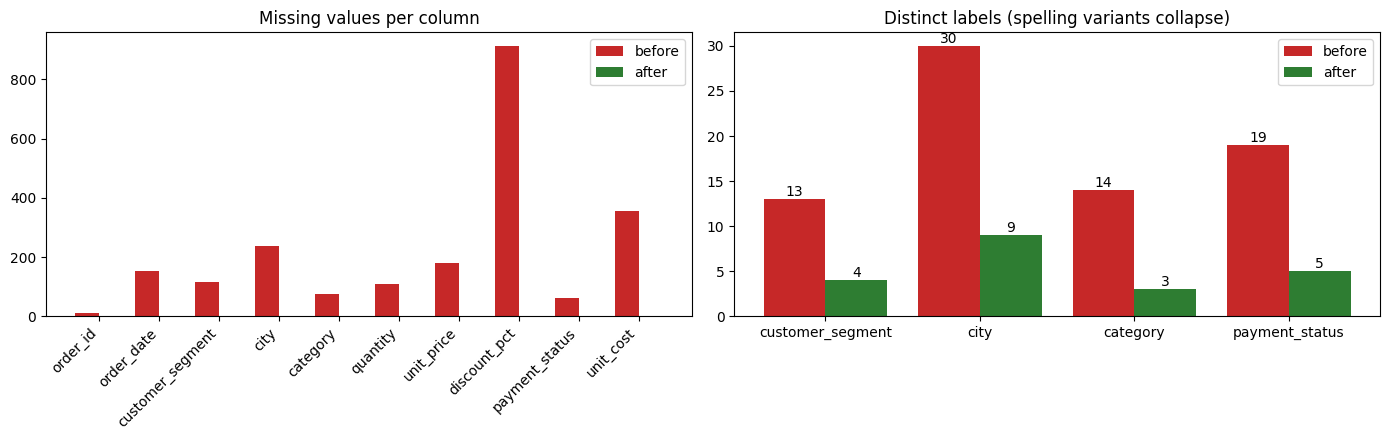

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cols = list(raw.columns)
x = np.arange(len(cols)); w = 0.4
axes[0].bar(x - w/2, miss_before.reindex(cols).values, w, label="before", color="#c62828")
axes[0].bar(x + w/2, clean.reindex(columns=cols).isna().sum().values, w, label="after", color="#2e7d32")
axes[0].set_xticks(x, cols, rotation=45, ha="right"); axes[0].set_title("Missing values per column"); axes[0].legend()
labs = ["customer_segment", "city", "category", "payment_status"]
b = [t[c].nunique() for c in labs]; a = [clean[c].nunique() for c in labs]
xx = np.arange(len(labs))
axes[1].bar(xx - w/2, b, w, label="before", color="#c62828"); axes[1].bar(xx + w/2, a, w, label="after", color="#2e7d32")
for i, (bb, aa) in enumerate(zip(b, a)):
    axes[1].text(i - w/2, bb, bb, ha="center", va="bottom"); axes[1].text(i + w/2, aa, aa, ha="center", va="bottom")
axes[1].set_xticks(xx, labs); axes[1].set_title("Distinct labels (spelling variants collapse)"); axes[1].legend()
plt.tight_layout(); plt.show()

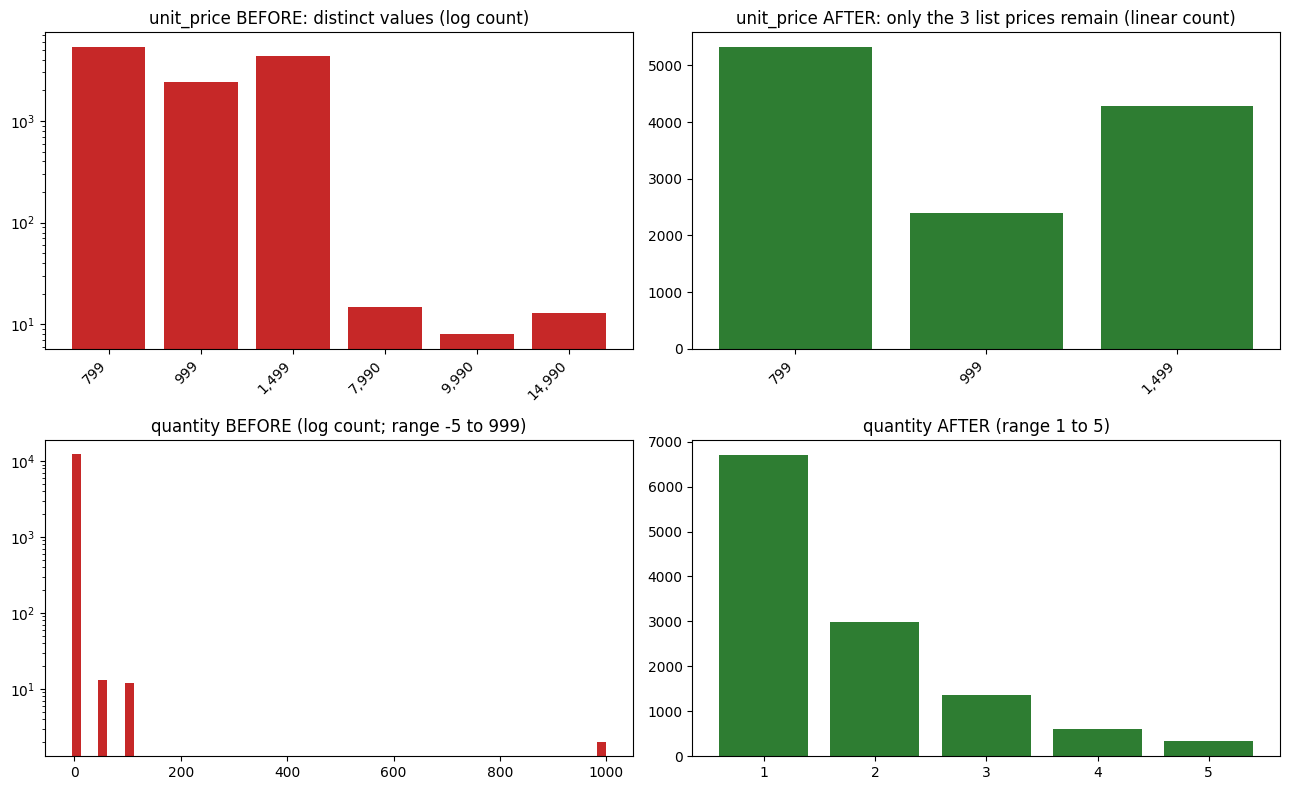

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
def price_counts(series):
    v = series.dropna(); v = v[v > 0].round(0)
    return v.value_counts().sort_index()
for ax, series, title, colr in [(axes[0, 0], BEFORE_NUM["unit_price"], "unit_price BEFORE: distinct values (log count)", "#c62828"),
                                (axes[0, 1], clean["unit_price"], "unit_price AFTER: only the 3 list prices remain (linear count)", "#2e7d32")]:
    vc_ = price_counts(series)
    ax.bar(range(len(vc_)), vc_.values, color=colr)
    if colr == "#c62828": ax.set_yscale("log")
    ax.set_xticks(range(len(vc_)), [f"{int(v):,}" for v in vc_.index], rotation=45, ha="right"); ax.set_title(title)
bq = BEFORE_NUM["quantity"].dropna()
axes[1, 0].hist(bq, bins=60, color="#c62828"); axes[1, 0].set_yscale("log"); axes[1, 0].set_title(f"quantity BEFORE (log count; range {bq.min():.0f} to {bq.max():.0f})")
vc = clean["quantity"].value_counts().sort_index()
axes[1, 1].bar(vc.index.astype(str), vc.values, color="#2e7d32"); axes[1, 1].set_title(f"quantity AFTER (range {clean['quantity'].min()} to {clean['quantity'].max()})")
plt.tight_layout(); plt.show()

Note: 2026-10 is a partial month (data ends 2026-10-10), excluded from the trend line.


,orders,net_revenue,avg_margin_pct
category,,,
Course Access,4276,10521031.3,68.1
Learning Kit,5317,6957771.9,41.5
Mentor Session,2396,3987408.6,51.9


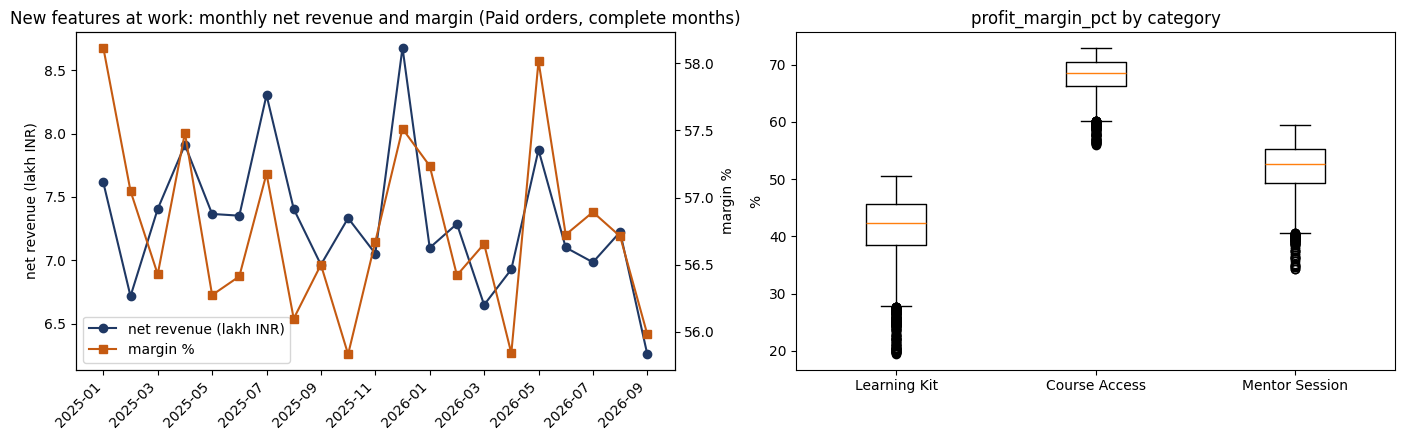

In [19]:
paid = clean[clean["is_paid"]]
monthly = paid.groupby("order_year_month").agg(net_revenue=("net_revenue", "sum"), profit=("gross_profit", "sum"))
monthly["margin_%"] = monthly["profit"] / monthly["net_revenue"] * 100
last_month_end = (pd.Period(monthly.index[-1]).end_time).normalize()
if clean["order_date"].max() < last_month_end:       # drop a partial final month so it does not look like a collapse
    print(f"Note: {monthly.index[-1]} is a partial month (data ends {clean['order_date'].max().date()}), excluded from the trend line.")
    monthly = monthly.iloc[:-1]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(monthly.index, monthly["net_revenue"] / 1e5, marker="o", color="#1f3864", label="net revenue (lakh INR)")
ax2 = axes[0].twinx(); ax2.plot(monthly.index, monthly["margin_%"], color="#c55a11", marker="s", label="margin %"); ax2.set_ylabel("margin %")
h1, l1 = axes[0].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); axes[0].legend(h1 + h2, l1 + l2, loc="lower left")
axes[0].set_xticks(range(0, len(monthly), 2), monthly.index[::2], rotation=45, ha="right"); axes[0].set_ylabel("net revenue (lakh INR)")
axes[0].set_title("New features at work: monthly net revenue and margin (Paid orders, complete months)")
axes[1].boxplot([clean.loc[clean["category"] == c, "profit_margin_pct"].dropna() for c in CATEGORIES], tick_labels=CATEGORIES)
axes[1].set_title("profit_margin_pct by category"); axes[1].set_ylabel("%")
plt.tight_layout(); plt.show()
display(clean.groupby("category", observed=True).agg(orders=("order_id", "count"), net_revenue=("net_revenue", "sum"), avg_margin_pct=("profit_margin_pct", "mean")).round(1))

## 8. Export the clean dataset
Written to `clean_dataset.csv`, then re-read from disk to prove the file round-trips with the right types.

In [20]:
clean.to_csv("clean_dataset.csv", index=False, date_format="%Y-%m-%d")
loaded = pd.read_csv("clean_dataset.csv", parse_dates=["order_date"])
assert loaded.shape == clean.shape and loaded["order_date"].dtype.kind == "M" and loaded["quantity"].dtype.kind == "i"
assert loaded.drop(columns="profit_margin_pct").notna().all().all() and loaded["order_id"].is_unique
print(f"clean_dataset.csv written: {loaded.shape[0]:,} rows x {loaded.shape[1]} columns; re-read OK")
loaded.dtypes.value_counts().rename("columns").to_frame().T

clean_dataset.csv written: 11,989 rows x 33 columns; re-read OK


,str,float64,bool,int64,datetime64[us]
columns,10,9,8,5,1


In [21]:
log_df = pd.DataFrame(LOG)
log_df.to_csv("cleaning_log.csv", index=False)
dropped_out = dropped_df.assign(source_row=dropped_df.index + 2)[["source_row", "drop_reason"] + list(raw.columns)]
dropped_out.to_csv("dropped_rows.csv", index=False)
print("cleaning_log.csv:", len(log_df), "entries  |  dropped_rows.csv:", len(dropped_out), "rows")
display(dropped_out["drop_reason"].value_counts().rename("rows").to_frame())
display(log_df.groupby("step")["affected"].sum().rename("cells/rows touched").to_frame())

cleaning_log.csv: 33 entries  |  dropped_rows.csv: 411 rows


,rows
drop_reason,
exact duplicate row,300
superseded by a later row with the same order_id,100
missing or malformed order_id,11


,cells/rows touched
step,
1 ids & duplicates,411
2 dates,2152
3 categoricals,4934
4 numbers,3825
5 features,14


## 9. Summary

In [22]:
n = len(raw)
print(f"Raw rows:            {n:,}")
print(f"Dropped:             {len(dropped_df):,}  ({', '.join(f'{k}: {v}' for k, v in dropped_df['drop_reason'].value_counts().items())})")
print(f"Clean rows:          {len(clean):,}  ({len(clean)/n:.1%} of raw retained)")
print(f"Rows with a fix:     {int((clean['n_fixes'] > 0).sum()):,} ({(clean['n_fixes'] > 0).mean():.1%}) - all flagged in the *_fixed / *_imputed / *_inferred columns")
print(f"Missing cells:       {BEFORE['Missing cells']:,} -> {AFTER['Missing cells']}")
print(f"Total net revenue:   INR {clean['net_revenue'].sum():,.0f}  | Paid: INR {clean.loc[clean['is_paid'], 'net_revenue'].sum():,.0f}")
print(f"Overall margin:      {clean['gross_profit'].sum() / clean['net_revenue'].sum():.1%}")

Raw rows:            12,400
Dropped:             411  (exact duplicate row: 300, superseded by a later row with the same order_id: 100, missing or malformed order_id: 11)
Clean rows:          11,989  (96.7% of raw retained)
Rows with a fix:     1,949 (16.3%) - all flagged in the *_fixed / *_imputed / *_inferred columns
Missing cells:       2,210 -> 0
Total net revenue:   INR 21,466,212  | Paid: INR 15,649,867
Overall margin:      56.7%


## 10. Same pipeline on your uploaded 12-row file
The functions above are composed into `run_pipeline` and applied to `retail-orders-raw.csv`. This file has **no `unit_cost` column**, so margins use the assumed cost ratios and every row says so in `margin_basis`; treat them as illustrative, not real profit.

In [23]:
def run_pipeline(raw_df):
    L, D = [], []
    lg = make_logger(L)
    x = step_ids_duplicates(tidy_text(raw_df), lg, D)
    x = step_dates(x, lg, D)
    x = step_categoricals(x, lg, D)
    x = step_numbers(x, lg, D)
    x = step_features(x, lg)
    return finalize(x), pd.DataFrame(L), pd.concat(D)

# the pipeline is deterministic: re-running it on the 12k file must reproduce clean_dataset.csv exactly
rerun, _, _ = run_pipeline(raw)
assert rerun.equals(clean), "pipeline is not reproducible"
print("reproducibility check: run_pipeline(raw) == clean_dataset  ->  OK\n")

sample_raw = pd.read_csv(SAMPLE_FILE, dtype=str, keep_default_na=False)
s_clean, s_log, s_dropped = run_pipeline(sample_raw)
print("RAW (uploaded file):"); display(sample_raw)
print("CLEAN:"); display(s_clean[["order_id", "order_date", "order_month", "customer_segment", "city", "category", "quantity", "unit_price", "discount_pct",
                                  "payment_status", "net_revenue", "profit_margin_pct", "margin_basis", "n_fixes"]])
print("What was dropped:"); display(s_dropped[["order_id", "drop_reason"]])
s_clean.to_csv("clean_dataset_uploaded_sample.csv", index=False, date_format="%Y-%m-%d")
print("Fixes applied:"); display(s_log.query("affected > 0")[["issue", "affected", "action"]])

reproducibility check: run_pipeline(raw) == clean_dataset  ->  OK

RAW (uploaded file):


,order_id,order_date,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status
0,RT-1001,2026-01-03,Student,Chennai,Learning Kit,2,799,10,Paid
1,RT-1002,03/01/2026,Fresher,Bengaluru,Course Access,1,1499,0,paid
2,RT-1003,2026-01-05,student,Chennai,Course Access,1,1499,,Pending
3,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5,Paid
4,RT-1004,2026-01-07,Professional,Hyderabad,Learning Kit,3,799,5,Paid
5,RT-1005,2026-01-09,Fresher,,Mentor Session,1,999,0,Failed
6,RT-1006,2026-13-10,Student,Pune,Learning Kit,-1,799,10,Paid
7,RT-1007,2026-01-12,Professional,Mumbai,Mentor Session,2,999,105,Paid
8,RT-1008,2026-01-14,Fresher,Bengaluru,Course Access,two,1499,0,Pending
9,RT-1009,2026-01-16,Student,Chennai,Learning Kit,1,799,0,Paid


CLEAN:


,order_id,order_date,order_month,customer_segment,city,category,quantity,unit_price,discount_pct,payment_status,net_revenue,profit_margin_pct,margin_basis,n_fixes
0,RT-1001,2026-01-03,1,Student,Chennai,Learning Kit,2,799.0,10.0,Paid,1438.20,38.89,assumed cost ratio,0
1,RT-1002,2026-01-03,1,Fresher,Bengaluru,Course Access,1,1499.0,0.0,Paid,1499.00,70.00,assumed cost ratio,0
2,RT-1003,2026-01-05,1,Student,Chennai,Course Access,1,1499.0,0.0,Pending,1499.00,70.00,assumed cost ratio,1
3,RT-1004,2026-01-07,1,Professional,Hyderabad,Learning Kit,3,799.0,5.0,Paid,2277.15,42.11,assumed cost ratio,0
4,RT-1005,2026-01-09,1,Fresher,Unknown,Mentor Session,1,999.0,0.0,Failed,999.00,55.00,assumed cost ratio,0
5,RT-1006,2026-01-10,1,Student,Pune,Learning Kit,1,799.0,10.0,Paid,719.10,38.89,assumed cost ratio,2
6,RT-1007,2026-01-12,1,Professional,Mumbai,Mentor Session,2,999.0,0.0,Paid,1998.00,55.00,assumed cost ratio,1
7,RT-1008,2026-01-14,1,Fresher,Bengaluru,Course Access,2,1499.0,0.0,Pending,2998.00,70.00,assumed cost ratio,0
8,RT-1009,2026-01-16,1,Student,Chennai,Learning Kit,1,799.0,0.0,Paid,799.00,45.00,assumed cost ratio,0
9,RT-1010,2026-01-18,1,Professional,Delhi,Course Access,2,1499.0,15.0,Refunded,2548.30,64.71,assumed cost ratio,0


What was dropped:


,order_id,drop_reason
4,RT-1004,exact duplicate row


Fixes applied:


,issue,affected,action
1,exact duplicate rows,1,"kept first copy, dropped the rest"
3,"non-ISO formats (DD/MM/YYYY, DD-Mon-YYYY, YYYY/MM/DD)",1,"parsed with explicit formats, stored as real dates"
4,"impossible calendar dates (month 13, 30 Feb, month 00)",1,set to null
7,missing order_date,1,set to null
8,null dates inferred from neighbouring orders,2,"midpoint of neighbours (<= 7 days apart), flagged date_imputed"
10,customer_segment: 4 spellings -> 3 labels,1,case/whitespace/alias/fuzzy standardisation
13,payment_status: 5 spellings -> 4 labels,1,case/whitespace/alias/fuzzy standardisation
15,city: missing,1,labelled 'Unknown' (not guessed)
17,"quantity written as words / decimals ('two', '2.0')",1,converted to integer
18,"quantity <= 0, fractional, unparseable or > 20 (outliers)",1,"set to null, then imputed"
